# Soft Copeland scores


### Defining helpers, functions, noisy labeler

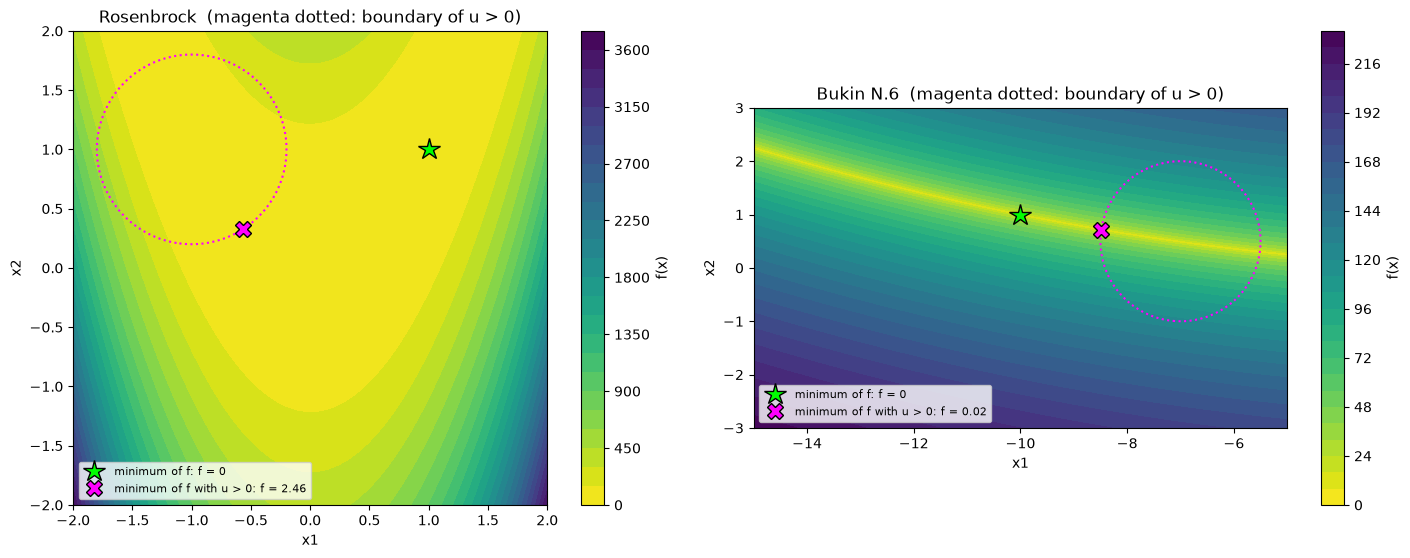

In [2]:
import sys, time, warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.special import expit
from scipy.stats import norm, spearmanr

for folder in (Path.cwd(), Path.cwd().parent):
    if (folder / "BOproj").is_dir():
        sys.path.insert(0, str(folder))
        break

from BOproj.benchmarks import ROSEN_BOUNDS, grid_optimum, neg_rosenbrock, rosenbrock, u_polynomial
from BOproj.bo_loop import BayesianOptimizer, initial_design
from BOproj.copeland import SoftCopeland
from BOproj.gp import PreferenceGP

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100


class NoisyPairwiseLabeler:
    """DM with Gaussian noise on each utility: a wins iff u(a) + noise_a > u(b) + noise_b, noise ~ N(0, sigma^2)."""

    def __init__(self, utility, sigma, seed=0):
        self.utility, self.sigma, self.rng = utility, sigma, np.random.default_rng(seed)

    def __call__(self, xa, xb):
        noise = self.sigma * self.rng.standard_normal((2, len(xa)))
        return self.utility(xa) + noise[0] > self.utility(xb) + noise[1]


BUKIN_BOUNDS = [[-15.0, -5.0], [-3.0, 3.0]]


def bukin_n6(X):
    """Minimised: f = 100 sqrt(|x2 - 0.01 x1^2|) + 0.01 |x1 + 10|.  Minimum 0 at (-10, 1), at the end of a very narrow
    curved ridge x2 = 0.01 x1^2 whose floor rises only by 0.01 per unit of x1: hard for any surrogate."""
    return 100 * np.sqrt(np.abs(X[:, 1] - 0.01 * X[:, 0] ** 2)) + 0.01 * np.abs(X[:, 0] + 10)


def neg_bukin_n6(X):
    return -bukin_n6(X)


def u_bukin(X):
    """Accept a disc of radius 1.5 around (-7, 0.5), which lies on the ridge; the minimum (-10, 1) is rejected."""
    return 1 - ((X[:, 0] + 7) ** 2 + (X[:, 1] - 0.5) ** 2) / 1.5 ** 2


PROBLEMS = {
    "Rosenbrock": dict(objective=neg_rosenbrock, bounds=ROSEN_BOUNDS, utility=u_polynomial, shown=rosenbrock,
                       optimum=(1.0, 1.0), ridge=None),
    "Bukin N.6": dict(objective=neg_bukin_n6, bounds=BUKIN_BOUNDS, utility=u_bukin, shown=bukin_n6,
                      optimum=(-10.0, 1.0), ridge=lambda x1: 0.01 * x1 ** 2),
}


def best_acceptable(problem):
    """(x, f) of the best design with u > 0 (f maximised).  A grid cannot resolve Bukin's ridge (its floor is a
    fraction of a grid cell wide), so a problem with a ridge also searches along it."""
    accept = lambda X: problem["utility"](X) > 0
    x, f = grid_optimum(problem["objective"], problem["bounds"], accept=accept)
    if problem["ridge"] is not None:
        line = np.linspace(*problem["bounds"][0], 20001)
        X = np.c_[line, problem["ridge"](line)]
        values = np.where(accept(X), problem["objective"](X), -np.inf)
        if values.max() > f:
            x, f = X[values.argmax()], values.max()
    return x, f


# the three acquisitions: name -> the preference score multiplying EI (None: plain log EI, no decision maker)
VARIANTS = {"log EI": None, "log EI + log pi": "probability", "log EI + log Copeland": "copeland"}
n_bo_steps, sigma_dm, n_landmarks = 25, 0.5, 64


# the two functions (minimised; the loop maximises their negative), the DM's accepted region u > 0, and the optima
fig, axes = plt.subplots(1, len(PROBLEMS), figsize=(7.5 * len(PROBLEMS), 5.6))
for axis, (name, problem) in zip(axes, PROBLEMS.items()):
    box = np.asarray(problem["bounds"])
    grid_1, grid_2 = np.meshgrid(np.linspace(*box[0], 300), np.linspace(*box[1], 300))
    X_grid = np.c_[grid_1.ravel(), grid_2.ravel()]
    values = problem["shown"](X_grid)
    shown = axis.contourf(grid_1, grid_2, values.reshape(grid_1.shape), 30, cmap="viridis_r")
    fig.colorbar(shown, ax=axis, label="f(x)")
    axis.contour(grid_1, grid_2, problem["utility"](X_grid).reshape(grid_1.shape), [0], colors="magenta", linestyles=":")
    x_acceptable, f_acceptable = best_acceptable(problem)
    axis.plot(*problem["optimum"], "*", color="lime", ms=16, mec="k", label="minimum of f: f = 0")
    axis.plot(*x_acceptable, "X", color="magenta", ms=11, mec="k", label=f"minimum of f with u > 0: f = {-f_acceptable:.2f}")
    axis.set(title=f"{name}  (magenta dotted: boundary of u > 0)", xlabel="x1", ylabel="x2", aspect="equal")
    axis.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()


In [3]:
def noisy_answers(problem, n_comparisons=30, seed=0):
    """n_comparisons noisy DM answers about random pairs of 30 lhs designs: (first, second, first_wins)."""
    designs = initial_design(problem["bounds"], 30, "lhs", seed=7)
    rng = np.random.default_rng(seed)
    first = rng.integers(0, len(designs), n_comparisons)
    second = (first + rng.integers(1, len(designs), n_comparisons)) % len(designs)
    first_wins = NoisyPairwiseLabeler(problem["utility"], sigma_dm)(designs[first], designs[second])
    return designs[first], designs[second], first_wins


def fit_preference_gp(problem, answers, n_comparisons):
    """A PreferenceGP fitted to the first n_comparisons of the answers (so the 5 are contained in the 10, and so on)."""
    first, second, first_wins = (part[:n_comparisons] for part in answers)
    return PreferenceGP(bounds=problem["bounds"], link="probit").fit(first, second, first_wins)


## How the Copeland score is computed

For a candidate $x$ the score is the mean of $\pi(x \succ x_k)$ over the $M$ fixed landmarks, so for $n$ candidates we need an $n \times M$ matrix. 
$\pi(x \succ x_k)$ needs the joint posterior of $u(x)$ and $u(x_k)$, so the candidates are cut into **chunks**: one chunk is one joint posterior over [the chunk's candidates, all landmarks], and it fills one block (a band of rows) of the matrix. 
The blocks are stacked, and $C(x)$ is each row's mean. Below, a 24 x 24 grid is cut into chunks of 100 candidates (the code uses 500). The learned utility is fitted on 30 comparisons.

576 candidates, 64 landmarks -> matrix (576, 64), 6 chunks of up to 100 candidates: [100, 100, 100, 100, 100, 76]


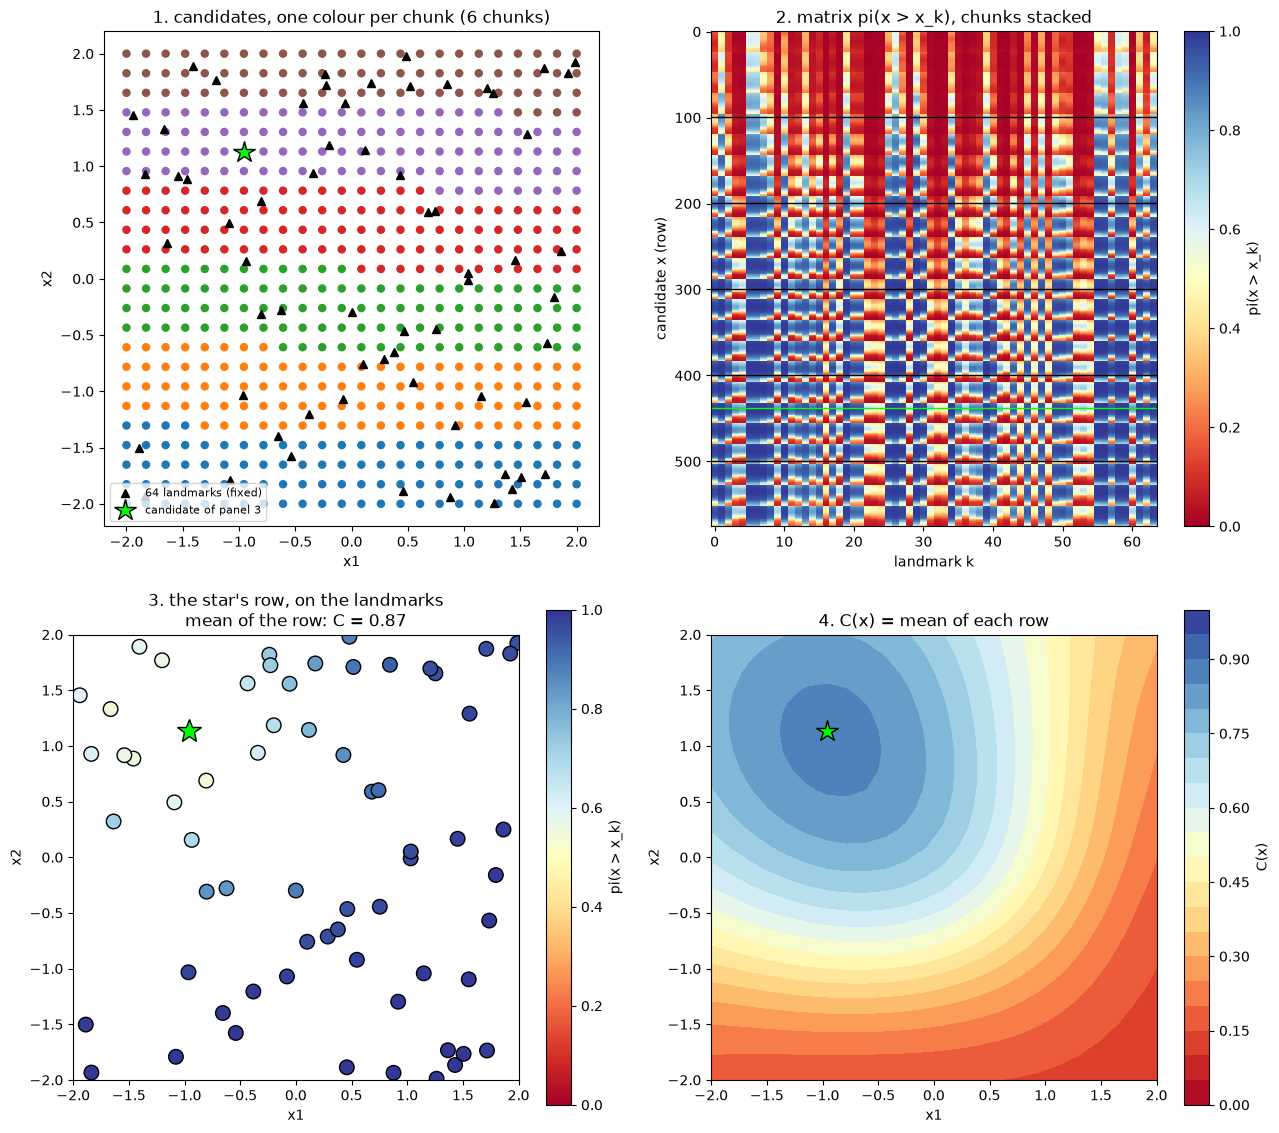

In [4]:
def show_chunks(problem, gp, landmarks, n_per_side=24, chunk_size=100):
    """The algorithm on a grid of candidates: (1) the candidates cut into chunks, (2) the matrix pi(x > x_k) filled
    chunk by chunk (rows: candidates, columns: landmarks), (3) one candidate's row on the landmarks, (4) C(x) = row mean."""
    box = np.asarray(problem["bounds"])
    grid_1, grid_2 = np.meshgrid(np.linspace(*box[0], n_per_side), np.linspace(*box[1], n_per_side))
    X = np.c_[grid_1.ravel(), grid_2.ravel()]
    starts = list(range(0, len(X), chunk_size))
    chunk_of = np.repeat(np.arange(len(starts)), chunk_size)[:len(X)]

    with torch.no_grad():
        # one chunk = one joint posterior over [the chunk's candidates, all landmarks]  ->  a (chunk, M) block
        blocks = [gp.prob_better_matrix_torch(X[start:start + chunk_size], landmarks) for start in starts]
        matrix = torch.cat(blocks).numpy()                                    # (n candidates, M landmarks)
        assert np.allclose(matrix, gp.prob_better_matrix_torch(X, landmarks, chunk_size=chunk_size).numpy())
        copeland = matrix.mean(axis=1)                                        # C(x): mean over the landmarks
        assert np.allclose(copeland, gp.soft_copeland_torch(X, landmarks).numpy())
    print(f"{len(X)} candidates, {len(landmarks)} landmarks -> matrix {matrix.shape}, "
          f"{len(starts)} chunks of up to {chunk_size} candidates: {[len(block) for block in blocks]}")
    best = copeland.argmax()                                                  # the candidate shown in panel 3

    fig, axes = plt.subplots(2, 2, figsize=(13, 11.5))
    axis = axes[0][0]
    axis.scatter(*X.T, c=chunk_of, cmap="tab10", vmin=-0.5, vmax=9.5, s=26)
    axis.plot(*landmarks.T, "k^", ms=6, label=f"{len(landmarks)} landmarks (fixed)")
    axis.plot(*X[best], "*", color="lime", ms=16, mec="k", label="candidate of panel 3")
    axis.set(title=f"1. candidates, one colour per chunk ({len(starts)} chunks)", xlabel="x1", ylabel="x2", aspect="equal")
    axis.legend(fontsize=8, loc="lower left")

    axis = axes[0][1]
    image = axis.imshow(matrix, aspect="auto", cmap="RdYlBu", vmin=0, vmax=1, interpolation="nearest")
    for start in starts[1:]:
        axis.axhline(start - 0.5, color="k", lw=1)
    axis.axhline(best, color="lime", lw=1)
    fig.colorbar(image, ax=axis, label="pi(x > x_k)")
    axis.set(title="2. matrix pi(x > x_k), chunks stacked", xlabel="landmark k", ylabel="candidate x (row)")

    axis = axes[1][0]
    shown = axis.scatter(*landmarks.T, c=matrix[best], cmap="RdYlBu", vmin=0, vmax=1, s=110, edgecolors="k")
    fig.colorbar(shown, ax=axis, label="pi(x > x_k)")
    axis.plot(*X[best], "*", color="lime", ms=18, mec="k")
    axis.set(title=f"3. the star's row, on the landmarks\nmean of the row: C = {copeland[best]:.2f}",
             xlabel="x1", ylabel="x2", xlim=box[0], ylim=box[1], aspect="equal")

    axis = axes[1][1]
    shown = axis.contourf(grid_1, grid_2, copeland.reshape(grid_1.shape), np.linspace(0, 1, 21), cmap="RdYlBu")
    fig.colorbar(shown, ax=axis, label="C(x)")
    axis.plot(*X[best], "*", color="lime", ms=16, mec="k")
    axis.set(title="4. C(x) = mean of each row", xlabel="x1", ylabel="x2", aspect="equal")
    plt.tight_layout()
    plt.show()


demo_problem = PROBLEMS["Rosenbrock"]
demo_gp = fit_preference_gp(demo_problem, noisy_answers(demo_problem), 30)
demo_landmarks = initial_design(demo_problem["bounds"], n_landmarks, "random", seed=0)
show_chunks(demo_problem, demo_gp, demo_landmarks)


In [5]:
def compare_chunking(problem, gp, landmarks, sides=(23, 48), chunk_size=100, repeats=3):
    """The matrix pi(x > x_k) with the candidates cut into chunks and in one piece (one joint posterior over all the
    candidates and the landmarks): same values? how long does each take (best of `repeats`)?"""
    box = np.asarray(problem["bounds"])
    print(f"{'candidates':>10s} {'chunked (' + str(chunk_size) + ')':>14s} {'one piece':>11s} {'slower by':>10s} {'max |difference|':>18s}")
    for side in sides:
        grid_1, grid_2 = np.meshgrid(np.linspace(*box[0], side), np.linspace(*box[1], side))
        X = np.c_[grid_1.ravel(), grid_2.ravel()]
        seconds, matrices = {}, {}
        with torch.no_grad():
            gp.prob_better_matrix_torch(X[:chunk_size], landmarks)             # warm-up, not timed
        for label, size in (("chunked", chunk_size), ("one piece", len(X))):
            times = []
            for _ in range(repeats):
                start = time.perf_counter()
                with torch.no_grad():
                    matrices[label] = gp.prob_better_matrix_torch(X, landmarks, chunk_size=size)
                times.append(time.perf_counter() - start)
            seconds[label] = min(times)
        difference = float((matrices["chunked"] - matrices["one piece"]).abs().max())
        print(f"{len(X):10d} {seconds['chunked']:13.3f}s {seconds['one piece']:10.3f}s "
              f"{seconds['one piece'] / seconds['chunked']:9.1f}x {difference:18.1e}")


compare_chunking(demo_problem, demo_gp, demo_landmarks)


candidates  chunked (100)   one piece  slower by   max |difference|
       529         0.130s      0.078s       0.6x            2.4e-14
      2304         0.193s      0.585s       3.0x            3.0e-14


## The Copeland score on its own

$C(x) = \frac{1}{M}\sum_k \pi(x \succ x_k)$ over $M$ = 64 fixed landmarks drawn uniformly in the bounds, on a preference GP fitted to 5, 10 and 30 noisy answers (the same answers, so the 5 are the first 5 of the 10, and so on; no BO):
- **reference, probit:** from the true utility, $\Phi\big((u(x) - u(x_k))/\sqrt2\big)$ averaged over the landmarks (the model the loop fits).
- **reference, logistic:** from the true utility, $1/\big(1 + e^{-(u(x) - u(x_k))}\big)$ averaged over the landmarks (the link of González et al. 2017, eq. 2).
- **learned $C(x)$:** what the loop uses (`soft_copeland_torch`, González et al. 2017, eqs. 4-5): the GP's posterior mean **and variance** of $u(x) - u(x_k)$ integrated out in closed form, $\Phi\big(\Delta m / \sqrt{2 + \Delta v}\big)$, averaged over the landmarks.

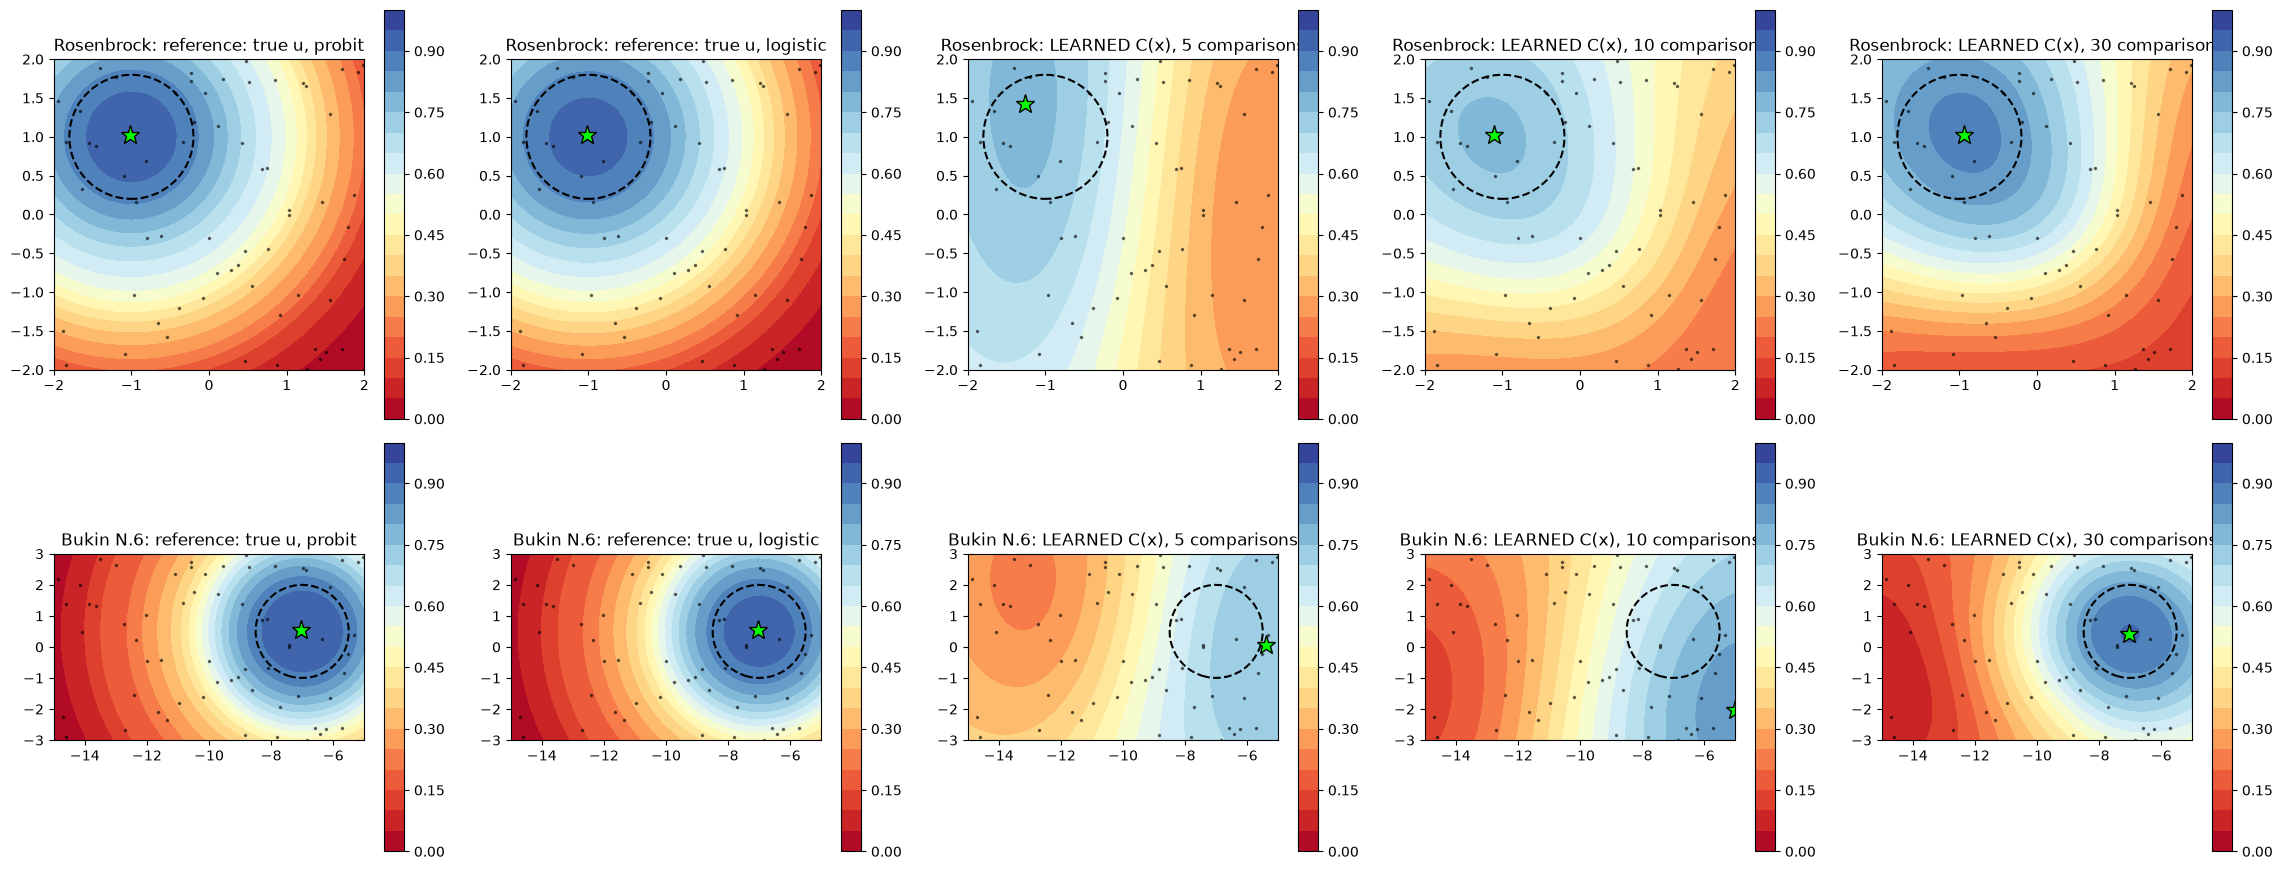

problem          version                              mean  median    min    max  rank corr. with probit truth
Rosenbrock       reference: true u, probit           0.519   0.536  0.000  0.934                         1.000
Rosenbrock       reference: true u, logistic         0.519   0.534  0.000  0.923                         1.000
Rosenbrock       LEARNED C(x), 5 comparisons         0.522   0.553  0.251  0.768                         0.796
Rosenbrock       LEARNED C(x), 10 comparisons        0.508   0.504  0.201  0.761                         0.993
Rosenbrock       LEARNED C(x), 30 comparisons        0.507   0.503  0.128  0.869                         0.988

Bukin N.6        reference: true u, probit           0.474   0.453  0.000  0.945                         1.000
Bukin N.6        reference: true u, logistic         0.473   0.461  0.001  0.932                         1.000
Bukin N.6        LEARNED C(x), 5 comparisons         0.478   0.447  0.232  0.749                         0.849


In [6]:
comparison_counts = (5, 10, 30)


def true_copeland(problem, landmarks, X, link):
    """Reference: mean over the landmarks of the probability that x beats x_k when the true utility u is known.
    probit:   Phi((u(x) - u(x_k)) / sqrt 2)         the model of the loop (Chu and Ghahramani 2005, BoTorch's probit likelihood)
    logistic: 1 / (1 + exp(-(u(x) - u(x_k))))      González et al. 2017, eq. 2 (BoTorch's logit likelihood)"""
    utility = problem["utility"]
    difference = utility(X)[:, None] - utility(landmarks)[None, :]
    probability = norm.cdf(difference / np.sqrt(2)) if link == "probit" else expit(difference)
    return probability.mean(axis=1)


def learned_copeland(gp, landmarks, X):
    """The score the loop uses: the (cached) SoftCopeland of the fitted preference GP over the fixed landmarks."""
    with torch.no_grad():
        return SoftCopeland(gp, landmarks).prepare()(X).numpy()


def show_copeland_alone(problems):
    """Per problem: the Copeland score from the true utility (reference) and the learned one with 5, 10, 30 comparisons,
    then a table of summary statistics and the rank correlation of each learned score with the reference."""
    scores_alone = {}
    columns = 2 + len(comparison_counts)
    fig, axes = plt.subplots(len(problems), columns, figsize=(4.6 * columns, 4.4 * len(problems)), facecolor="white",
                             squeeze=False)
    for row, (name, problem) in zip(axes, problems.items()):
        box = np.asarray(problem["bounds"])
        grid_1, grid_2 = np.meshgrid(np.linspace(*box[0], 50), np.linspace(*box[1], 50))
        X_grid = np.c_[grid_1.ravel(), grid_2.ravel()]
        landmarks = initial_design(problem["bounds"], n_landmarks, "random", seed=0)        # fixed once
        answers = noisy_answers(problem)
        scores = {"reference: true u, probit": true_copeland(problem, landmarks, X_grid, "probit"),
                  "reference: true u, logistic": true_copeland(problem, landmarks, X_grid, "logistic")}
        for n_comparisons in comparison_counts:
            gp = fit_preference_gp(problem, answers, n_comparisons)
            scores[f"LEARNED C(x), {n_comparisons} comparisons"] = learned_copeland(gp, landmarks, X_grid)
        scores_alone[name] = scores
        for axis, (version, values) in zip(row, scores.items()):
            shown = axis.contourf(grid_1, grid_2, values.reshape(grid_1.shape), np.linspace(0, 1, 21), cmap="RdYlBu")
            fig.colorbar(shown, ax=axis)
            axis.contour(grid_1, grid_2, problem["utility"](X_grid).reshape(grid_1.shape), [0], colors="k", linestyles="--")
            axis.plot(*landmarks.T, ".", color="k", ms=3, alpha=0.5)
            axis.plot(*X_grid[values.argmax()], "*", color="lime", ms=14, mec="k")
            axis.set(title=f"{name}: {version}", aspect="equal")
    plt.tight_layout()
    plt.show()

    print(f"{'problem':16s} {'version':34s} {'mean':>6s} {'median':>7s} {'min':>6s} {'max':>6s} {'rank corr. with probit truth':>29s}")
    for name, scores in scores_alone.items():
        truth = scores["reference: true u, probit"]
        for version, values in scores.items():
            print(f"{name:16s} {version:34s} {values.mean():6.3f} {np.median(values):7.3f} {values.min():6.3f} {values.max():6.3f} "
                  f"{spearmanr(values, truth)[0]:29.3f}")
        print()


show_copeland_alone(PROBLEMS)


## Soft Copeland scores on another utility function

Same check as above, with the decision maker's utility $u = 3\,\sin(2\pi z_1)\,\sin(\pi z_2)$ ($z$ = the design scaled to $[0,1]^2$) instead of the polynomial: one accepted half of the box ($u>0$) with its best point at its centre, and a mirror-image worst half.

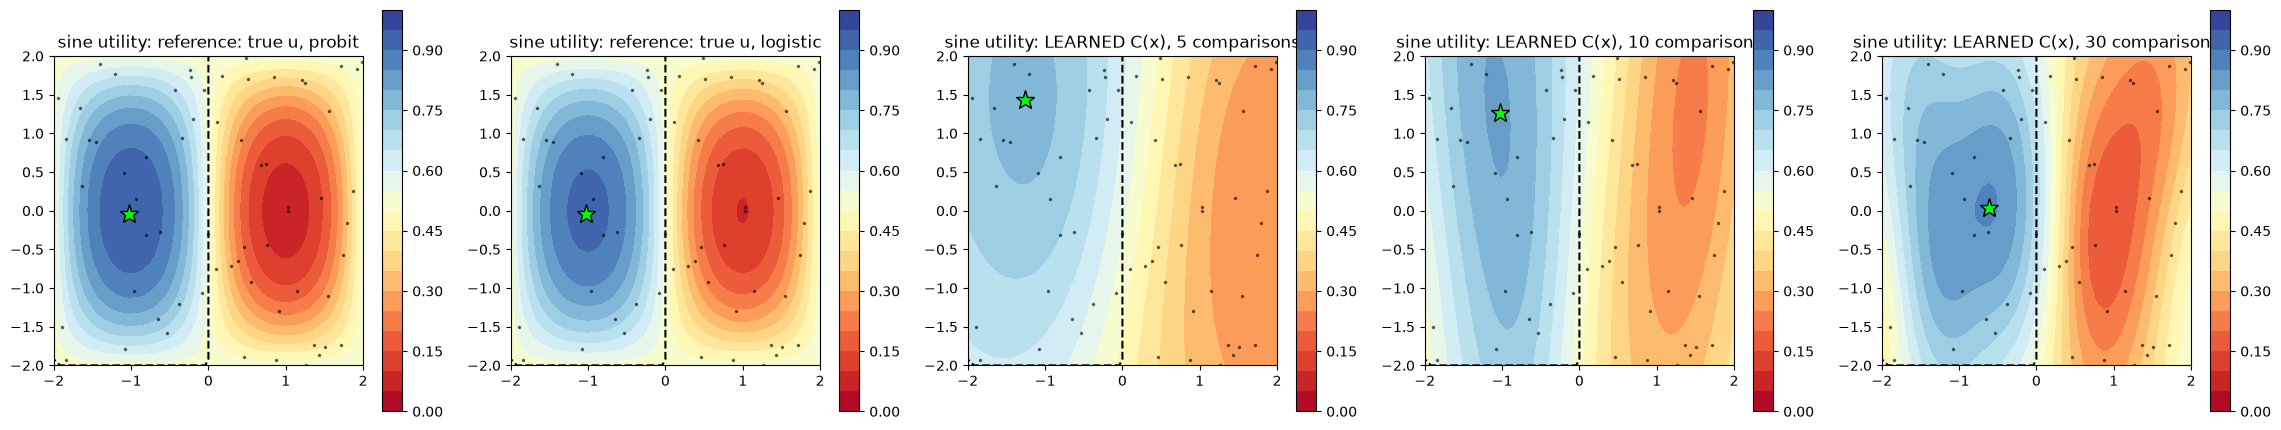

problem          version                              mean  median    min    max  rank corr. with probit truth
sine utility     reference: true u, probit           0.522   0.529  0.072  0.941                         1.000
sine utility     reference: true u, logistic         0.520   0.526  0.098  0.917                         1.000
sine utility     LEARNED C(x), 5 comparisons         0.522   0.553  0.251  0.768                         0.797
sine utility     LEARNED C(x), 10 comparisons        0.525   0.550  0.235  0.806                         0.885
sine utility     LEARNED C(x), 30 comparisons        0.529   0.563  0.154  0.854                         0.948



In [7]:
def sine_utility(bounds, amplitude=3.0):
    """u = amplitude * sin(2 pi z1) * sin(pi z2), z = the design scaled to [0, 1]^2: the DM likes the half of the box with
    z1 < 0.5 (u > 0), best at its centre, and dislikes the mirror-image half"""
    box = np.asarray(bounds)

    def utility(X):
        z = (X - box[:, 0]) / (box[:, 1] - box[:, 0])
        return amplitude * np.sin(2 * np.pi * z[:, 0]) * np.sin(np.pi * z[:, 1])
    return utility

rosenbrock_box = PROBLEMS["Rosenbrock"]
SINE_PROBLEMS = {"sine utility": {**rosenbrock_box, "utility": sine_utility(rosenbrock_box["bounds"])}}
show_copeland_alone(SINE_PROBLEMS)


## Bayesian Optimization Runs

Six BO runs (two problems x three acquisitions), one cell per acquisition so they can be run separately. Running a cell recomputes its runs. Running the next cell (the one defining `run_variant`) empties `results`, so run the three acquisition cells again after it.

In [8]:
def run_variant(problem, preference_score):
    """One BO run of the problem; preference_score is None (plain log EI), "probability" or "copeland"."""
    if preference_score is None:
        optimizer = BayesianOptimizer(problem["objective"], problem["bounds"], seed=0)
    else:                                          # a noisy decision maker answers comparisons of 30 designs
        optimizer = BayesianOptimizer(problem["objective"], problem["bounds"], seed=0,
                                      comparer=NoisyPairwiseLabeler(problem["utility"], sigma_dm),
                                      X_pref=initial_design(problem["bounds"], 30, "lhs", seed=7),
                                      preference_score=preference_score, n_landmarks=n_landmarks)
    return optimizer.run(n_bo_steps)


def run_on_all_problems(variant):
    """Run one acquisition on every problem and store the runs in `results` (always recomputed)."""
    for name, problem in PROBLEMS.items():
        results[name][variant] = run_variant(problem, VARIANTS[variant])


results = {name: {} for name in PROBLEMS}          # filled by the three cells below


### log EI

In [9]:
run_on_all_problems("log EI")

### log EI + log pi

In [10]:
run_on_all_problems("log EI + log pi")

### log EI + log Copeland

In [11]:
run_on_all_problems("log EI + log Copeland")

## Plotting the results

Rows: problem. Columns: acquisition. Green star: the maximum of $f$ over the box; magenta cross: the maximum of $f$ among the designs the DM accepts ($u > 0$, magenta dotted line).

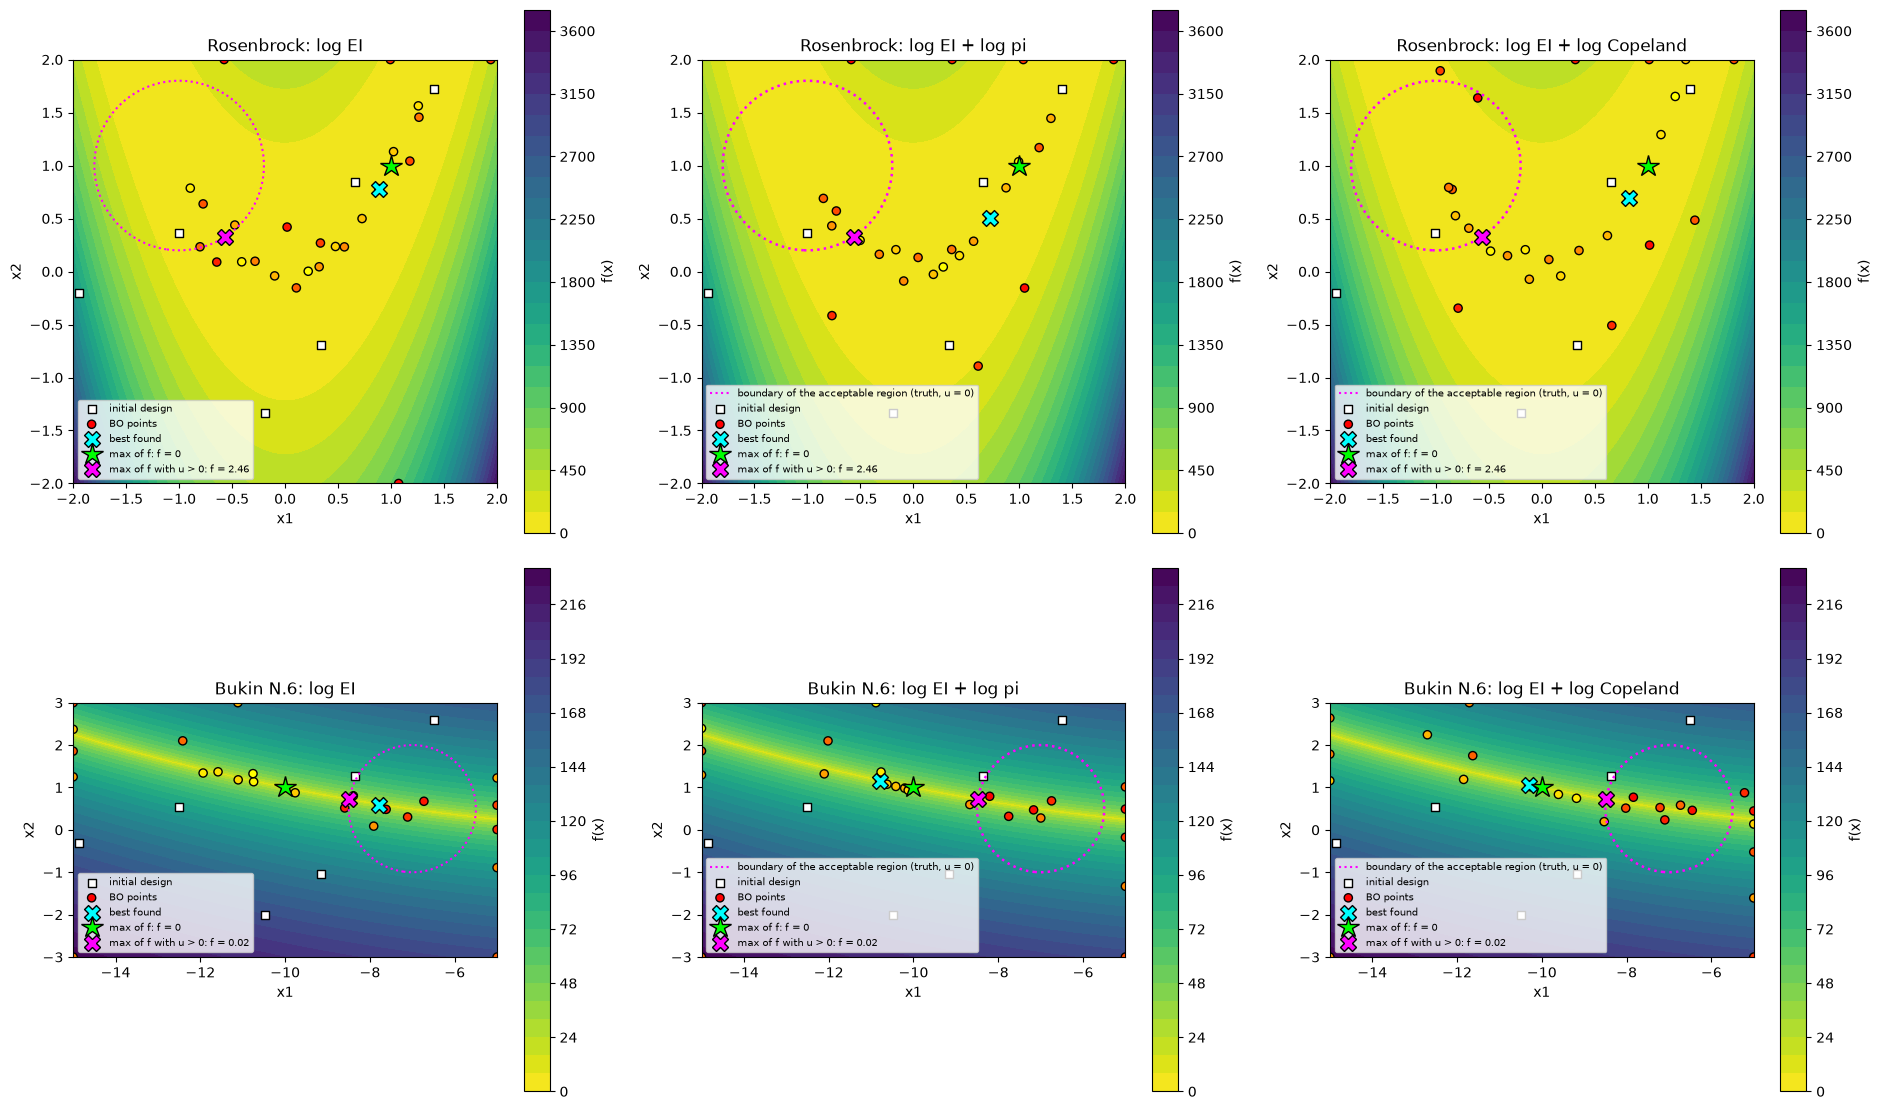

In [12]:
fig, axes = plt.subplots(len(PROBLEMS), len(VARIANTS), figsize=(19, 5.6 * len(PROBLEMS)))
for row, (name, problem) in zip(axes, PROBLEMS.items()):
    x_acceptable, f_acceptable = best_acceptable(problem)
    box = np.asarray(problem["bounds"])
    grid_1, grid_2 = np.meshgrid(np.linspace(*box[0], 200), np.linspace(*box[1], 200))
    X_grid = np.c_[grid_1.ravel(), grid_2.ravel()]
    for axis, (variant, run) in zip(row, results[name].items()):
        run.plot_points(ax=axis, background=problem["shown"], step_colorbar=False, title=f"{name}: {variant}")
        if run.comparer is None:                                     # plot_points draws u = 0 itself when there is a DM
            axis.contour(grid_1, grid_2, problem["utility"](X_grid).reshape(grid_1.shape), [0], colors="magenta", linestyles=":")
        axis.plot(*problem["optimum"], "*", color="lime", ms=16, mec="k", label="max of f: f = 0")
        axis.plot(*x_acceptable, "X", color="magenta", ms=11, mec="k", label=f"max of f with u > 0: f = {-f_acceptable:.2f}")
        axis.legend(fontsize=7, loc="lower left")
plt.tight_layout()
plt.show()

## The terms of the acquisition

The loop maximises $\mathrm{EI}(x)\,\pi(x)$ (or $\mathrm{EI}(x)\,C(x)$ for Copeland). In the code this is computed as $\log \mathrm{EI} + \log \pi$, which has the same maximiser because the log is increasing, and does not underflow: $\mathrm{EI}$ is $\approx 10^{-1000}$ in the corners, which a float cannot hold (the product would be $0$ and its gradient too).
The maps below are the plain values: $\mathrm{EI}$, the score ($\pi$ or the Copeland value, between 0 and 1) and their product, after `acquisition_step` BO steps. Red star: the point the loop chose next.
First row of a pair: every map has its own colour range and colour bar. Second row: one colour scale and one colour bar for all three maps, so the same number has the same colour everywhere.

Rosenbrock, log EI + log pi, after 16 evaluations:  max EI 17.991,  pi(x) from 0.34 to 0.90,  max EI x score 15.148
Rosenbrock, log EI + log Copeland, after 16 evaluations:  max EI 17.399,  Copeland value C(x) from 0.13 to 0.87,  max EI x score 8.731


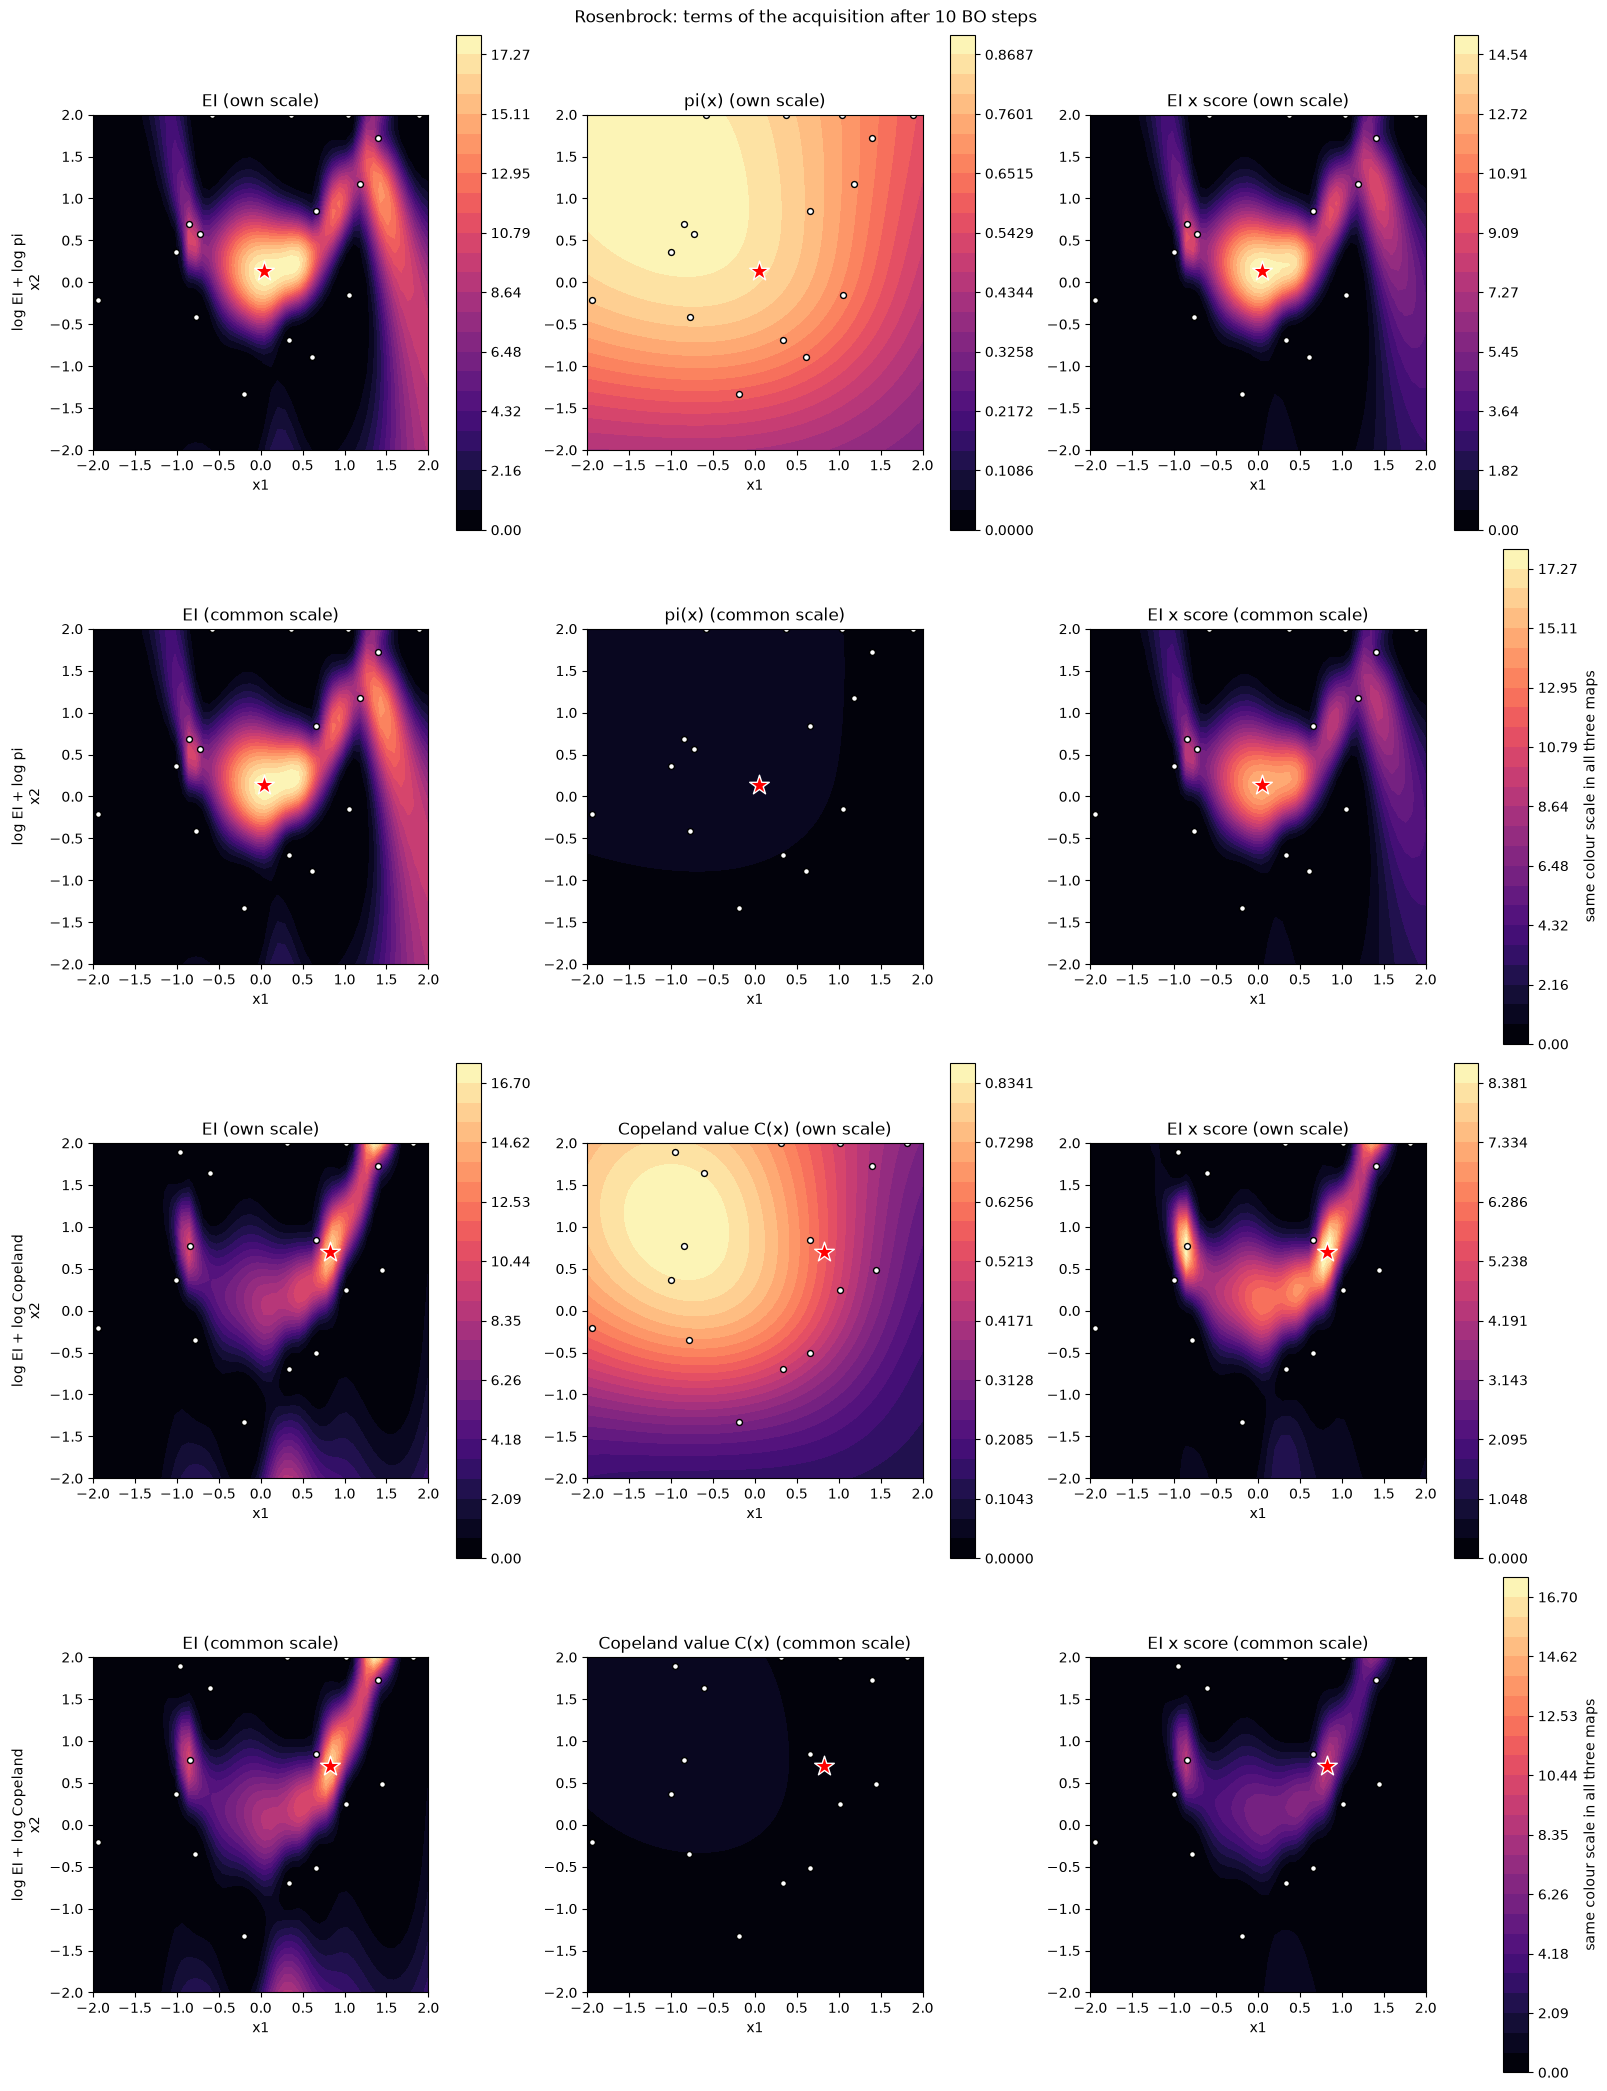

Bukin N.6, log EI + log pi, after 16 evaluations:  max EI 0.020,  pi(x) from 0.20 to 0.95,  max EI x score 0.011
Bukin N.6, log EI + log Copeland, after 16 evaluations:  max EI 0.571,  Copeland value C(x) from 0.05 to 0.90,  max EI x score 0.089


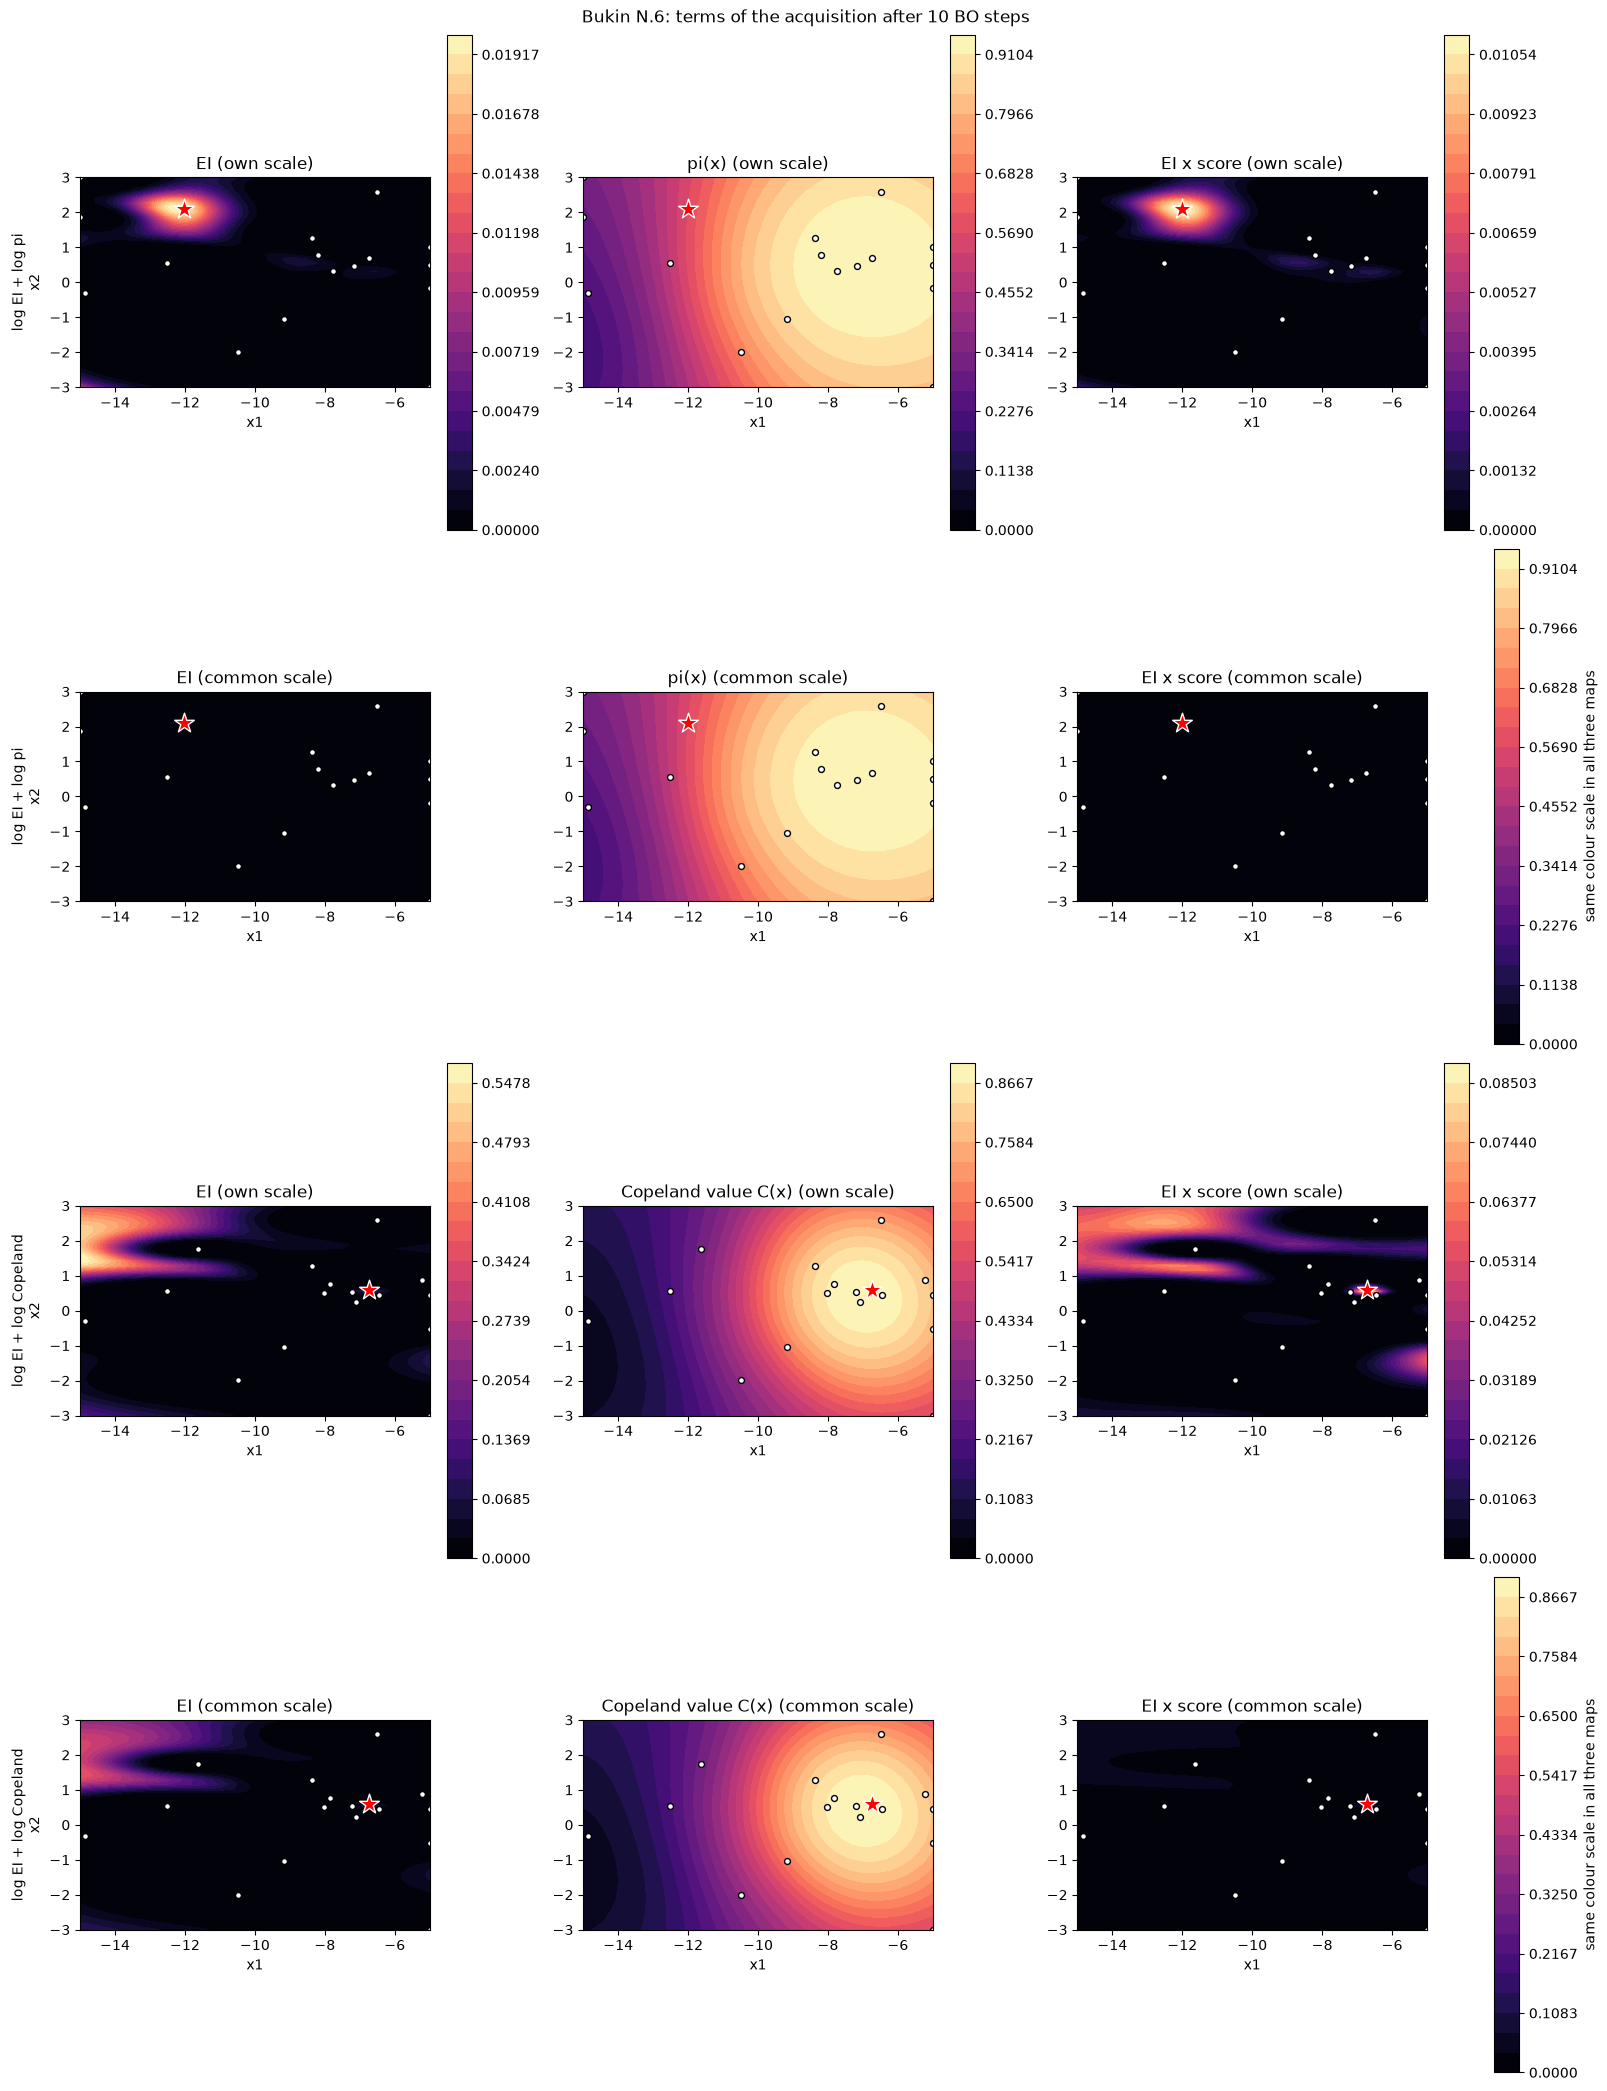

In [13]:
acquisition_step = 10          # BO steps done when the acquisition is drawn (the star is the point chosen next)
PREFERENCE_VARIANTS = ["log EI + log pi", "log EI + log Copeland"]
SCORE_NAME = {"log EI + log pi": "pi(x)", "log EI + log Copeland": "Copeland value C(x)"}


def acquisition_terms(run, n_evaluations, grid=50):
    """EI, the preference score (pi or Copeland value, in [0, 1]) and their product on a grid, for the acquisition
    that chose evaluation n_evaluations.  The loop works with the logs; they are exponentiated here only for the maps
    (EI underflows to 0 in the far corners, which is what it is there)."""
    acquisition = run.acquisition(n_evaluations)
    box = np.asarray(run.bounds)
    grid_1, grid_2 = np.meshgrid(np.linspace(*box[0], grid), np.linspace(*box[1], grid))
    X_grid = np.c_[grid_1.ravel(), grid_2.ravel()]
    X_batch = torch.as_tensor(X_grid[:, None, :], dtype=torch.float64)         # q = 1 per point: no n x n covariance
    with torch.no_grad():
        log_ei, log_score = acquisition.log_ei(X_batch).numpy(), acquisition.log_pref(X_batch).numpy()
    shape = grid_1.shape
    return grid_1, grid_2, {"EI": np.exp(log_ei).reshape(shape), "score": np.exp(log_score).reshape(shape),
                            "EI x score": np.exp(log_ei + log_score).reshape(shape)}


def show_terms(name, step=acquisition_step):
    """Per variant two rows.  Own scale: every map has its own colour range and colour bar.  Common scale: all three
    maps use the same range, 0 to the largest value of the three, and one colour bar: the same number is the same
    colour in every map, so a score between 0 and 1 is nearly black next to an EI of 17."""
    fig, axes = plt.subplots(2 * len(PREFERENCE_VARIANTS), 3, figsize=(16, 5.2 * 2 * len(PREFERENCE_VARIANTS)),
                             layout="constrained")
    for pair, variant in enumerate(PREFERENCE_VARIANTS):
        run = results[name][variant]
        n = run.n_init + step
        grid_1, grid_2, terms = acquisition_terms(run, n)
        top = max(values.max() for values in terms.values())
        for row, scale in ((2 * pair, "own scale"), (2 * pair + 1, "common scale")):
            axes[row][0].set_ylabel(f"{variant}\nx2")
            for axis, (term, values) in zip(axes[row], terms.items()):
                high = values.max() if scale == "own scale" else top
                shown = axis.contourf(grid_1, grid_2, values, np.linspace(0, high, 26), cmap="magma")
                if scale == "own scale":
                    fig.colorbar(shown, ax=axis)
                axis.scatter(*run.X[:n].T, c="w", edgecolors="k", s=18)
                axis.scatter(*run.X[n], marker="*", c="red", edgecolors="w", s=220)
                axis.set(title=f"{SCORE_NAME[variant] if term == 'score' else term} ({scale})", xlabel="x1",
                         ylabel=axis.get_ylabel(), aspect="equal")
            if scale == "common scale":
                fig.colorbar(shown, ax=list(axes[row]), label="same colour scale in all three maps")
        print(f"{name}, {variant}, after {n} evaluations:  max EI {terms['EI'].max():.3f},  "
              f"{SCORE_NAME[variant]} from {terms['score'].min():.2f} to {terms['score'].max():.2f},  "
              f"max EI x score {terms['EI x score'].max():.3f}")
    fig.suptitle(f"{name}: terms of the acquisition after {step} BO steps")
    plt.show()


for name in PROBLEMS:
    show_terms(name)


## Summary

Share of the BO points (after the initial design) that the DM accepts ($u > 0$), and the best $f$ among all evaluated designs with $u > 0$ (the true best acceptable value is in the last column; lower is better, both are values of the minimised function).

In [14]:
print(f"{'problem':16s} {'acquisition':24s} {'BO points with u > 0':>21s} {'best f with u > 0':>18s} {'true best, u > 0':>17s}")
for name, problem in PROBLEMS.items():
    _, f_acceptable = best_acceptable(problem)
    for variant, run in results[name].items():
        accepted = problem["utility"](run.X) > 0
        best = -np.max(run.y[accepted]) if accepted.any() else float("nan")
        print(f"{name:16s} {variant:24s} {np.mean(accepted[run.n_init:]):21.0%} {best:18.4f} {-f_acceptable:17.4f}")

problem          acquisition               BO points with u > 0  best f with u > 0  true best, u > 0
Rosenbrock       log EI                                     16%             3.3020            2.4608
Rosenbrock       log EI + log pi                            12%             3.1590            2.4608
Rosenbrock       log EI + log Copeland                      20%             3.2827            2.4608
Bukin N.6        log EI                                     24%             9.8766            0.0152
Bukin N.6        log EI + log pi                            20%            20.6657            0.0152
Bukin N.6        log EI + log Copeland                      24%             7.8228            0.0152
